In [3]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.home() / "UltraCNN"
DATASET_ROOT = PROJECT_ROOT / "data" / "kitti" / "stereo2012"

print("Project:", PROJECT_ROOT)
print("Dataset:", DATASET_ROOT)
print("Dataset directory exists:", DATASET_ROOT.exists())

Project: /home/ghost/UltraCNN
Dataset: /home/ghost/UltraCNN/data/kitti/stereo2012
Dataset directory exists: True


In [4]:
for path in sorted(DATASET_ROOT.rglob("*")):
    if path.is_dir():
        print(f"[DIR]  {path.relative_to(DATASET_ROOT)}")

[DIR]  data_stereo_flow
[DIR]  data_stereo_flow/testing
[DIR]  data_stereo_flow/testing/calib
[DIR]  data_stereo_flow/testing/colored_0
[DIR]  data_stereo_flow/testing/colored_1
[DIR]  data_stereo_flow/testing/image_0
[DIR]  data_stereo_flow/testing/image_1
[DIR]  data_stereo_flow/training
[DIR]  data_stereo_flow/training/calib
[DIR]  data_stereo_flow/training/colored_0
[DIR]  data_stereo_flow/training/colored_1
[DIR]  data_stereo_flow/training/disp_noc
[DIR]  data_stereo_flow/training/disp_occ
[DIR]  data_stereo_flow/training/disp_refl_noc
[DIR]  data_stereo_flow/training/disp_refl_occ
[DIR]  data_stereo_flow/training/flow_noc
[DIR]  data_stereo_flow/training/flow_occ
[DIR]  data_stereo_flow/training/image_0
[DIR]  data_stereo_flow/training/image_1
[DIR]  data_stereo_flow_calib
[DIR]  data_stereo_flow_calib/testing
[DIR]  data_stereo_flow_calib/testing/calib
[DIR]  data_stereo_flow_calib/training
[DIR]  data_stereo_flow_calib/training/calib


In [5]:
left_dirs = [
    p for p in DATASET_ROOT.rglob("colored_0")
    if p.is_dir()
]

right_dirs = [
    p for p in DATASET_ROOT.rglob("colored_1")
    if p.is_dir()
]

print("Left image directories:")
for p in left_dirs:
    print(p)

print("\nRight image directories:")
for p in right_dirs:
    print(p)

Left image directories:
/home/ghost/UltraCNN/data/kitti/stereo2012/data_stereo_flow/training/colored_0
/home/ghost/UltraCNN/data/kitti/stereo2012/data_stereo_flow/testing/colored_0

Right image directories:
/home/ghost/UltraCNN/data/kitti/stereo2012/data_stereo_flow/training/colored_1
/home/ghost/UltraCNN/data/kitti/stereo2012/data_stereo_flow/testing/colored_1


In [6]:
if not left_dirs or not right_dirs:
    raise FileNotFoundError(
        "Could not find colored_0 and colored_1. "
        "Check the extracted KITTI directory structure."
    )

left_dir = left_dirs[0]
right_dir = next(
    (
        p for p in right_dirs
        if p.parent == left_dir.parent
    ),
    None
)

if right_dir is None:
    raise FileNotFoundError(
        "Could not find a matching right-image directory."
    )

left_images = sorted(left_dir.glob("*.png"))

if not left_images:
    raise FileNotFoundError(
        f"No PNG images found in {left_dir}"
    )

left_path = left_images[0]
right_path = right_dir / left_path.name

if not right_path.exists():
    raise FileNotFoundError(
        f"Matching right image not found: {right_path}"
    )

left_image = cv2.imread(str(left_path))
right_image = cv2.imread(str(right_path))

if left_image is None or right_image is None:
    raise RuntimeError("Failed to read one or both images.")

print("Left image:", left_path.name)
print("Left dimensions:", left_image.shape)
print("Right dimensions:", right_image.shape)

Left image: 000000_10.png
Left dimensions: (370, 1226, 3)
Right dimensions: (370, 1226, 3)


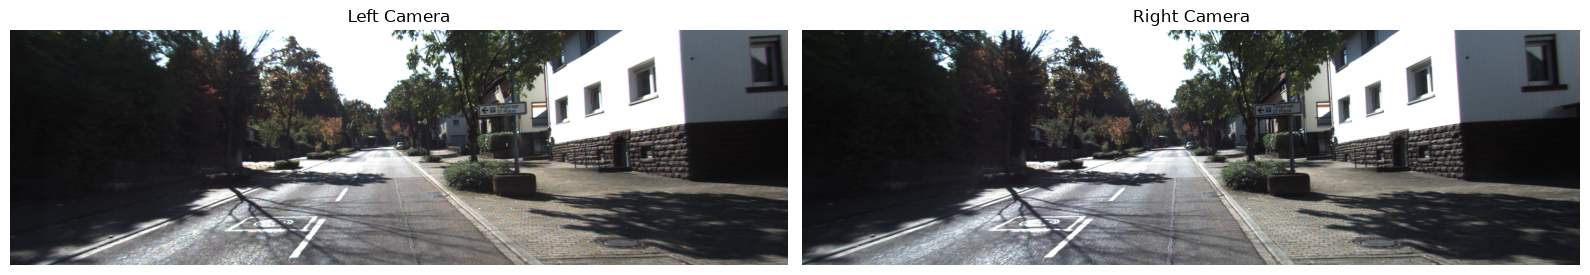

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(cv2.cvtColor(left_image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Left Camera")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(right_image, cv2.COLOR_BGR2RGB))
axes[1].set_title("Right Camera")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [8]:
assert left_image.shape == right_image.shape, (
    "Left and right image dimensions do not match."
)

height, width = left_image.shape[:2]

print(f"Image width:  {width} pixels")
print(f"Image height: {height} pixels")
print(f"Image size:   {width * height:,} pixels")

Image width:  1226 pixels
Image height: 370 pixels
Image size:   453,620 pixels


Left image shape: (370, 1226, 3)
Right image shape: (370, 1226, 3)


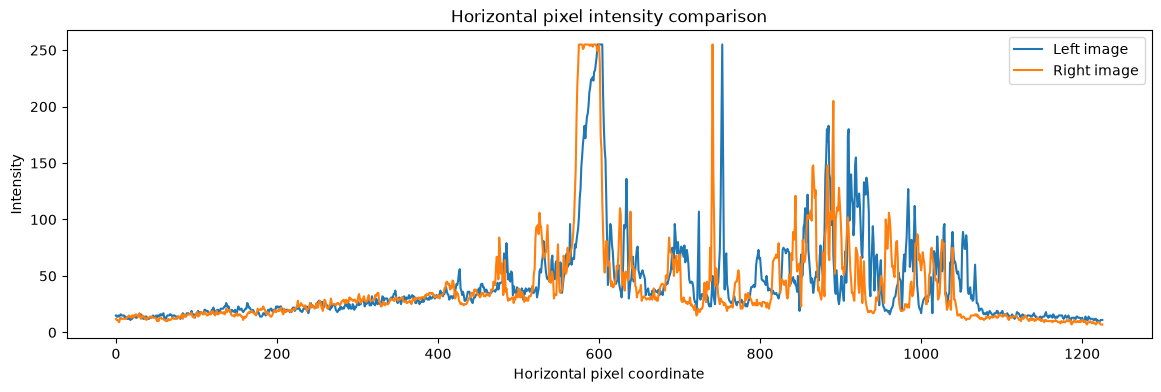

In [9]:
print("Left image shape:", left_image.shape)
print("Right image shape:", right_image.shape)

# Display a horizontal slice from both images
row = left_image.shape[0] // 2

plt.figure(figsize=(14, 4))
plt.plot(left_image[row, :, 0], label="Left image")
plt.plot(right_image[row, :, 0], label="Right image")
plt.title("Horizontal pixel intensity comparison")
plt.xlabel("Horizontal pixel coordinate")
plt.ylabel("Intensity")
plt.legend()
plt.show()

In [10]:
from pathlib import Path

calib_root = DATASET_ROOT / "data_stereo_flow_calib"

calib_files = sorted(calib_root.rglob("*.txt"))

print("Number of calibration files:", len(calib_files))

for path in calib_files[:10]:
    print(path.relative_to(DATASET_ROOT))

Number of calibration files: 389
data_stereo_flow_calib/testing/calib/000000.txt
data_stereo_flow_calib/testing/calib/000001.txt
data_stereo_flow_calib/testing/calib/000002.txt
data_stereo_flow_calib/testing/calib/000003.txt
data_stereo_flow_calib/testing/calib/000004.txt
data_stereo_flow_calib/testing/calib/000005.txt
data_stereo_flow_calib/testing/calib/000006.txt
data_stereo_flow_calib/testing/calib/000007.txt
data_stereo_flow_calib/testing/calib/000008.txt
data_stereo_flow_calib/testing/calib/000009.txt


In [11]:
import numpy as np

if not calib_files:
    raise FileNotFoundError(
        f"No calibration .txt files found under {calib_root}"
    )

calib_path = calib_files[0]

calibration = {}

with open(calib_path, "r") as file:
    for line in file:
        if ":" not in line:
            continue

        key, values = line.split(":", 1)

        try:
            calibration[key.strip()] = np.array(
                [float(x) for x in values.split()]
            )
        except ValueError:
            continue

print("Calibration file:", calib_path.name)
print("Available calibration keys:", list(calibration.keys()))

Calibration file: 000000.txt
Available calibration keys: ['P0', 'P1', 'P2', 'P3']


In [12]:
for key in ["P2", "P3"]:
    if key in calibration:
        print(f"\n{key}:")
        print(calibration[key].reshape(3, 4))


P2:
[[ 7.188560e+02  0.000000e+00  6.071928e+02  4.538225e+01]
 [ 0.000000e+00  7.188560e+02  1.852157e+02 -1.130887e-01]
 [ 0.000000e+00  0.000000e+00  1.000000e+00  3.779761e-03]]

P3:
[[ 7.188560e+02  0.000000e+00  6.071928e+02 -3.372877e+02]
 [ 0.000000e+00  7.188560e+02  1.852157e+02  2.369057e+00]
 [ 0.000000e+00  0.000000e+00  1.000000e+00  4.915215e-03]]


In [13]:
if "P2" not in calibration or "P3" not in calibration:
    raise KeyError(
        "P2/P3 were not found. Inspect the available calibration keys "
        "and we'll adapt the parser to your calibration format."
    )

P2 = calibration["P2"].reshape(3, 4)
P3 = calibration["P3"].reshape(3, 4)

focal_length = P2[0, 0]

left_camera_offset = P2[0, 3] / P2[0, 0]
right_camera_offset = P3[0, 3] / P3[0, 0]

baseline = abs(right_camera_offset - left_camera_offset)

print(f"Focal length: {focal_length:.3f} pixels")
print(f"Stereo baseline: {baseline:.4f} metres")

Focal length: 718.856 pixels
Stereo baseline: 0.5323 metres


In [14]:
# Convert stereo images to grayscale
left_gray = cv2.cvtColor(left_image, cv2.COLOR_BGR2GRAY)
right_gray = cv2.cvtColor(right_image, cv2.COLOR_BGR2GRAY)

# StereoSGBM parameters
window_size = 5
min_disparity = 0
num_disparities = 128

stereo = cv2.StereoSGBM_create(
    minDisparity=min_disparity,
    numDisparities=num_disparities,
    blockSize=window_size,
    P1=8 * window_size**2,
    P2=32 * window_size**2,
    disp12MaxDiff=1,
    uniquenessRatio=10,
    speckleWindowSize=100,
    speckleRange=2,
    mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY
)

print("StereoSGBM initialized.")
print("Image dimensions:", left_gray.shape)

StereoSGBM initialized.
Image dimensions: (370, 1226)


In [15]:
disparity_raw = stereo.compute(left_gray, right_gray)

# OpenCV StereoSGBM stores disparity with a scale factor of 16.
disparity = disparity_raw.astype(np.float32) / 16.0

valid_disparity = disparity > min_disparity

print("Disparity shape:", disparity.shape)
print("Valid disparity pixels:", valid_disparity.sum())
print(
    "Percentage of valid pixels:",
    f"{100 * valid_disparity.mean():.2f}%"
)

if valid_disparity.any():
    print(
        "Disparity range:",
        float(disparity[valid_disparity].min()),
        "to",
        float(disparity[valid_disparity].max()),
        "pixels"
    )

Disparity shape: (370, 1226)
Valid disparity pixels: 372268
Percentage of valid pixels: 82.07%
Disparity range: 1.0625 to 72.375 pixels


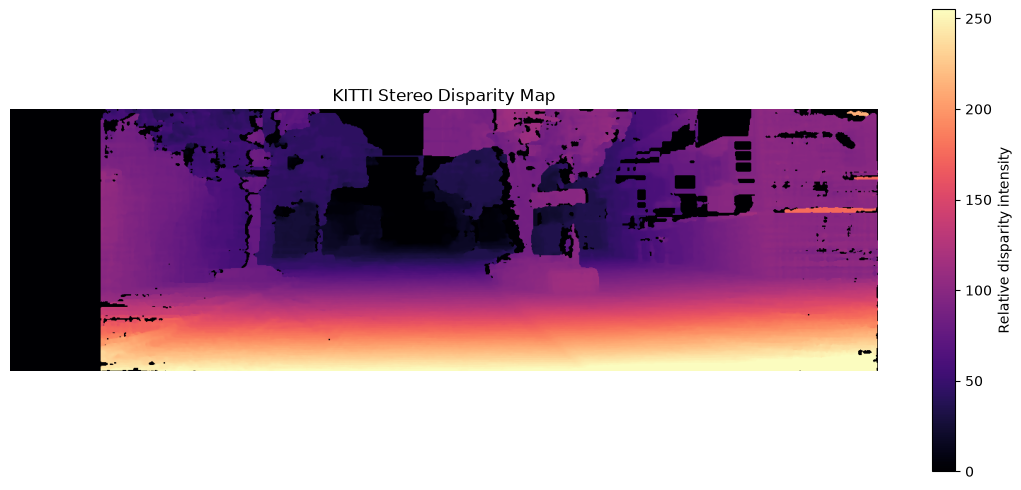

In [16]:
disparity_visual = np.zeros_like(disparity, dtype=np.uint8)

if valid_disparity.any():
    values = disparity[valid_disparity]

    low, high = np.percentile(values, [2, 98])

    if high > low:
        normalized = np.clip(
            (disparity - low) / (high - low),
            0,
            1
        )

        disparity_visual = (normalized * 255).astype(np.uint8)

        disparity_visual[~valid_disparity] = 0

plt.figure(figsize=(14, 6))

plt.imshow(disparity_visual, cmap="magma")
plt.title("KITTI Stereo Disparity Map")
plt.colorbar(label="Relative disparity intensity")
plt.axis("off")

plt.show()

In [17]:
depth = np.full(disparity.shape, np.nan, dtype=np.float32)

valid_depth = (
    np.isfinite(disparity)
    & (disparity > 0)
)

depth[valid_depth] = (
    focal_length * baseline / disparity[valid_depth]
)

print("Valid depth pixels:", np.isfinite(depth).sum())

if np.isfinite(depth).any():
    print(
        "Depth percentiles (metres):",
        np.nanpercentile(depth, [5, 25, 50, 75, 95])
    )

Valid depth pixels: 372268
Depth percentiles (metres): [ 6.4790678  10.10349751 14.57790279 21.25944138 48.21038818]


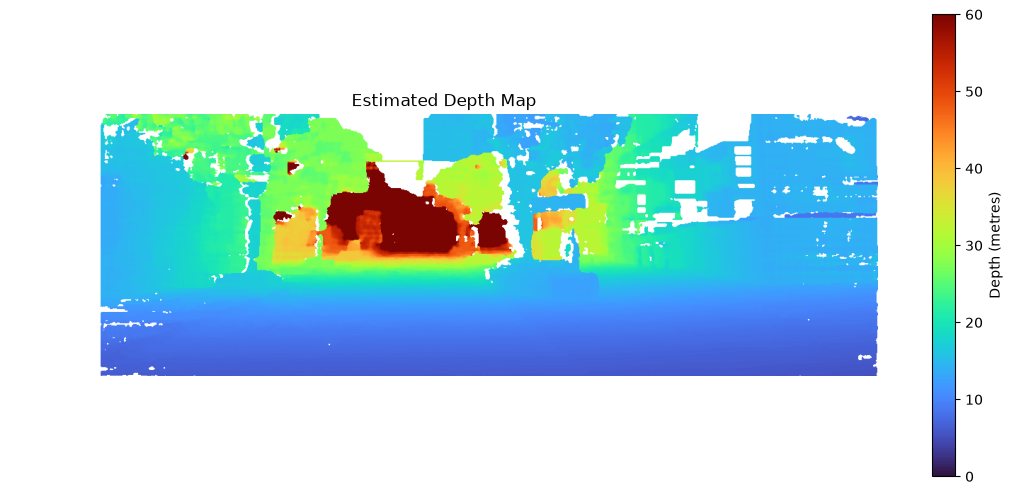

In [18]:
valid_depth = np.isfinite(depth) & (depth > 0)

depth_display = np.ma.masked_invalid(depth)

plt.figure(figsize=(14, 6))

plt.imshow(depth_display, cmap="turbo", vmin=0, vmax=60)
plt.title("Estimated Depth Map")
plt.colorbar(label="Depth (metres)")
plt.axis("off")

plt.show()